# E1 - MobileNetV3-Small Reworked AT-ADD Baseline (24 kHz + Repeat-Pad)

**Notebook:** `notebooks/reworked/E1/ATADD_E1_MobileNetV3Small_Reworked_24kHz_RepeatPad_seed1.ipynb`  
**Protocol:** Baseline E1 (MobileNetV3-Small, 24 kHz, 4.0s segment, Repeat-Padding, Seed 1: 42)  
**Dataset Split:** `data/manifests/AT_ADDReworked/` (100% Generator-Disjoint AND 100% Speaker-Disjoint)  
**Key Protocol Enhancements:**
1. **Class-Weighted Cross-Entropy Loss:** Inverse-frequency class weights ($w_{\text{real}} \approx 1.875, w_{\text{fake}} \approx 0.682$) to balance the 2.75:1 fake-to-real class imbalance in training.
2. **Gradient Norm Clipping (`MAX_GRAD_NORM = 5.0`):** Unscaled mixed-precision gradient clipping to limit batch outliers and stabilize training trajectory.
3. **Dual Decision-Threshold Reporting:** Evaluates official test sets under both fixed standard $\theta = 0.50$ and dev-calibrated $\theta^*$.
4. **Comprehensive Generalization Auditing:** Per-type (4 domains), per-generator (38 unseen zero-shot architectures), and seen vs. unseen real sources.

## Dataset & Output Directory Configuration

Targeting the reworked manifests under `data/manifests/AT_ADDReworked/`.
All artifacts are saved under dedicated `reworked/` directories:
- Checkpoints: `checkpoints/reworked/E1/`
- Experiments: `experiments/baselines/reworked/E1/`
- Tables: `results/tables/reworked/E1/`
- Figures: `results/figures/reworked/E1/`
- Logs: `results/logs/reworked/E1/`

# 1. Environment and project paths

This section imports the experiment libraries and locates the project root.

The notebook searches upward from the current working directory for the prepared AT-ADD manifest directory, so it can be run from the project root or `notebooks/`.

All experiment outputs are kept separate from the raw dataset.

In [1]:
# 1. Imports and project paths

from pathlib import Path
import json
import math
import random
import time
import warnings
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import mobilenet_v3_small

warnings.filterwarnings("ignore")


def find_project_root(start_path):
    start_path = Path(start_path).resolve()
    candidates = [start_path] + list(start_path.parents)
    for candidate in candidates:
        if (
            (candidate / "data" / "manifests" / "AT_ADDReworked" / "train_manifest.csv").exists()
            and (candidate / "src" / "preprocessing" / "preprocess_atadd_rerun.py").exists()
        ):
            return candidate
    for candidate in candidates:
        if (
            (candidate / "data" / "manifests" / "AT_ADD" / "train_manifest.csv").exists()
            and (candidate / "src" / "preprocessing" / "preprocess_atadd_rerun.py").exists()
        ):
            return candidate
    raise FileNotFoundError("Could not locate project root.")


PROJECT_ROOT = find_project_root(Path.cwd())
DATA_ROOT = PROJECT_ROOT / "data"

# Reworked speaker-and-generator disjoint manifests directory
MANIFEST_DIR = DATA_ROOT / "manifests" / "AT_ADDReworked"
TRAIN_MANIFEST = MANIFEST_DIR / "train_manifest.csv"
DEV_MANIFEST = MANIFEST_DIR / "dev_manifest.csv"
EVAL_MANIFEST = MANIFEST_DIR / "eval_manifest.csv"

# Dedicated reworked output directories
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints" / "reworked" / "E1"
EXPERIMENT_DIR = PROJECT_ROOT / "experiments" / "baselines" / "reworked" / "E1"
RESULT_TABLE_DIR = PROJECT_ROOT / "results" / "tables" / "reworked" / "E1"
RESULT_FIGURE_DIR = PROJECT_ROOT / "results" / "figures" / "reworked" / "E1"
RESULT_LOG_DIR = PROJECT_ROOT / "results" / "logs" / "reworked" / "E1"

for directory in [
    CHECKPOINT_DIR,
    EXPERIMENT_DIR,
    RESULT_TABLE_DIR,
    RESULT_FIGURE_DIR,
    RESULT_LOG_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing.preprocess_atadd_rerun import (
    cpu_prepare_waveform,
    GPULogMel,
    normalize_log_mel,
    compute_logmel_stats_gpu
)

print("Project root:", PROJECT_ROOT)
print("Manifest directory:", MANIFEST_DIR)
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Experiment directory:", EXPERIMENT_DIR)

Project root: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification
Manifest directory: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/AT_ADDReworked
Checkpoint directory: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/checkpoints/reworked/E1
Experiment directory: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E1


# 2. Verify the prepared dataset

The frozen AT-ADD manifests define the train, development, and evaluation partitions.

The notebook requires the core `name`, `label`, and `split` fields. If `file_id` is not present, it is derived from `name` so the same notebook works with the finalized manifests without modifying them.


In [2]:
# 2. Check the generated manifests before training

required_files=[
    TRAIN_MANIFEST,
    DEV_MANIFEST,
    EVAL_MANIFEST
]

for path in required_files:
    status="OK" if path.exists() else "MISSING"
    print(f"{status:<8} {path}")

if not TRAIN_MANIFEST.exists() or not DEV_MANIFEST.exists():
    raise FileNotFoundError(
        "Train/dev manifests were not found. "
        "Make sure the finalized AT-ADD manifests are present first."
    )


OK       /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/AT_ADDReworked/train_manifest.csv
OK       /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/AT_ADDReworked/dev_manifest.csv
OK       /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/AT_ADDReworked/eval_manifest.csv


# 3. Reproducibility and experiment configuration

E1 needs a fixed configuration so that later experiments can be compared fairly.

The important settings recorded here include:

- random seed
- audio sampling rate
- segment duration
- STFT parameters
- number of Mel bins
- batch size
- learning rate
- optimizer settings
- experiment version
- input preprocessing version

For the final E1 experiment, the fraction variables remain `None`, meaning the complete prepared partitions are used.



In [3]:
# 3. Reproducibility and training configuration

# -------------------------------------------------------------------------
# Multi-Seed Protocol:
# Fixed benchmark seeds: seed1: 42, seed2: 1337, seed3: 2024
# -------------------------------------------------------------------------
SEED_TAG = "seed2"  # 'seed1' | 'seed2' | 'seed3'
BENCHMARK_SEEDS = {
    "seed1": 42,
    "seed2": 1337,
    "seed3": 2024
}

if SEED_TAG not in BENCHMARK_SEEDS:
    raise ValueError(f"Unknown SEED_TAG: {SEED_TAG}. Must be one of {list(BENCHMARK_SEEDS.keys())}")

SEED = BENCHMARK_SEEDS[SEED_TAG]

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if DEVICE.type == "cuda":
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.set_float32_matmul_precision("high")
    print("Device:", torch.cuda.get_device_name(0))
else:
    print("Device: CPU")

EXPERIMENT_VERSION = f"v6.0_reworked_{SEED_TAG}"
INPUT_PREPROCESSING_VERSION = "24khz_repeat_pad_reworked"

# Training Hyperparameters
BATCH_SIZE = 32
EPOCHS = 25               # 25 epochs to train until convergence
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE = None           # Early stopping disabled - train full 35 epochs
MAX_GRAD_NORM = 5.0       # Gradient clipping norm threshold (mixed-precision unscaled)

NUM_WORKERS = 4
PREFETCH_FACTOR = 2

# Audio Feature Extraction Parameters (24 kHz Repeat-Padding Protocol)
SAMPLE_RATE = 24000
SEGMENT_SECONDS = 4
NUM_SAMPLES = SAMPLE_RATE * SEGMENT_SECONDS  # 96,000 samples

N_FFT = 1024
WIN_LENGTH = 600
HOP_LENGTH = 240
N_MELS = 80
LOG_EPS = 1e-10

# Set fractions to None for full production training
TRAIN_FRACTION = None
DEV_FRACTION = None
EVAL_FRACTION = None

STATS_MAX_FILES = None

print("Seed Tag:", SEED_TAG)
print("Active Seed:", SEED)
print("Experiment version:", EXPERIMENT_VERSION)
print("Input preprocessing version:", INPUT_PREPROCESSING_VERSION)
print("Batch size:", BATCH_SIZE)
print("Epochs budget:", EPOCHS)
print("Early stopping patience:", PATIENCE if PATIENCE is not None else "Disabled (train full 35 epochs)")
print("Max Gradient Norm Clip:", MAX_GRAD_NORM)
print("DataLoader workers:", NUM_WORKERS)
print("Device:", DEVICE)

Device: NVIDIA GeForce RTX 3060 Laptop GPU
Seed Tag: seed2
Active Seed: 1337
Experiment version: v6.0_reworked_seed2
Input preprocessing version: 24khz_repeat_pad_reworked
Batch size: 32
Epochs budget: 25
Early stopping patience: Disabled (train full 35 epochs)
Max Gradient Norm Clip: 5.0
DataLoader workers: 4
Device: cuda


# 4. Load the reproducible manifests

The finalized AT-ADD train/dev/eval manifests are read directly from `data/manifests/`.

The notebook does not recreate or modify the prepared splits. The same manifests can therefore be reused by E2/E3 for fair comparison.

In [4]:
# 4. Load the reproducible AT-ADD manifests

train_df=pd.read_csv(TRAIN_MANIFEST)
dev_df=pd.read_csv(DEV_MANIFEST)

if EVAL_MANIFEST.exists():
    eval_df=pd.read_csv(EVAL_MANIFEST)
else:
    eval_df=pd.DataFrame()


LABEL_MAP={"real":0,"fake":1}
INV_LABEL_MAP={0:"real",1:"fake"}

required_columns={
    "name",
    "label",
    "split"
}

for name,df in [
    ("train",train_df),
    ("dev",dev_df),
    ("eval",eval_df)
]:
    if len(df)==0:
        continue

    missing_columns=required_columns-set(df.columns)

    if missing_columns:
        raise ValueError(
            f"{name} manifest is missing required columns: {sorted(missing_columns)}"
        )

    if "file_id" not in df.columns:
        df["file_id"]=df["name"].astype(str)

    unknown_labels=set(
        df["label"].dropna().astype(str).unique()
    )-set(LABEL_MAP)

    if unknown_labels:
        raise ValueError(
            f"{name} contains unknown labels: {unknown_labels}"
        )

    expected_split=name

    if not set(df["split"].astype(str).unique())<={
        expected_split
    }:
        raise ValueError(
            f"{name} manifest contains an unexpected split value."
        )

print("Train:",len(train_df))
print("Dev:",len(dev_df))
print("Eval:",len(eval_df))

print("\nTrain columns:")
print(train_df.columns.tolist())

print("\nFirst training entries:")
display(train_df.head())


Train: 60000
Dev: 22536
Eval: 44289

Train columns:
['name', 'type', 'label', 'source', 'source_id', 'speaker_id', 'generation_task', 'generator', 'caption', 'split', 'folder', 'audio_path', 'file_id']

First training entries:


,name,type,label,source,source_id,speaker_id,generation_task,generator,caption,split,folder,audio_path,file_id
0,ATADD_T2_Train_138205.flac,music,fake,-,-,-,TTM,AudioLDM2,someone is playing a high pitched melody on a ...,train,train,data/raw/AT_ADD/train/ATADD_T2_Train_138205.flac,ATADD_T2_Train_138205.flac
1,ATADD_T2_Train_138216.flac,music,fake,-,-,-,TTM,AudioLDM2,This clip is an electronic guitar instrumental...,train,train,data/raw/AT_ADD/train/ATADD_T2_Train_138216.flac,ATADD_T2_Train_138216.flac
2,ATADD_T2_Train_138218.flac,music,fake,-,-,-,TTM,AudioLDM2,This is a drum & bass music piece. There is a ...,train,train,data/raw/AT_ADD/train/ATADD_T2_Train_138218.flac,ATADD_T2_Train_138218.flac
3,ATADD_T2_Train_138227.flac,music,fake,-,-,-,TTM,AudioLDM2,This is a country music piece. There is a fidd...,train,train,data/raw/AT_ADD/train/ATADD_T2_Train_138227.flac,ATADD_T2_Train_138227.flac
4,ATADD_T2_Train_138230.flac,music,fake,-,-,-,TTM,AudioLDM2,This music is a spirited instrumental. The tem...,train,train,data/raw/AT_ADD/train/ATADD_T2_Train_138230.flac,ATADD_T2_Train_138230.flac


## Dataset integrity checks

Before training, we check whether the paths recorded in the manifests actually point to audio files.

A missing file should be investigated before the final experiment rather than silently skipped.


In [5]:
# 5. Verify that manifest paths point to existing files

def audio_path_from_row(row, project_root):
    folder = row["folder"] if "folder" in row and pd.notna(row["folder"]) else row["split"]
    return project_root / "data" / "raw" / "AT_ADD" / str(folder) / str(row["name"])

def check_audio_files(df, project_root):
    if len(df) == 0:
        return 0
    return sum(
        not audio_path_from_row(row, project_root).exists()
        for _, row in df.iterrows()
    )

for name, df in [
    ("train", train_df),
    ("dev", dev_df),
    ("eval", eval_df)
]:
    if len(df) == 0:
        continue
    missing = check_audio_files(df, PROJECT_ROOT)
    print(f"{name:<8}: {missing} missing audio files (Total: {len(df):,})")
    assert missing == 0, f"Found missing files in {name}!"


train   : 0 missing audio files (Total: 60,000)
dev     : 0 missing audio files (Total: 22,536)
eval    : 0 missing audio files (Total: 44,289)


## Class and generator distribution

The class distribution is inspected before training because the prepared AT-ADD subset is not perfectly balanced.

Fake-generator coverage is also checked to confirm that the evaluation generators remain unseen during training and development. No split is modified here.

In [6]:
# 6. Inspect class, type, speaker, and generator information

def show_split_summary(df, name):
    print(f"\n{name.upper()}")
    print("-" * 50)
    print("Files:", len(df))

    if "label" in df.columns:
        print("\nClass counts:")
        print(df["label"].value_counts(dropna=False))

    if "type" in df.columns:
        print("\nAudio type counts:")
        print(df["type"].value_counts(dropna=False))

    if "generator" in df.columns:
        fake_df = df[df["label"] == "fake"]
        print("\nFake generators:", fake_df["generator"].nunique())

show_split_summary(train_df, "train")
show_split_summary(dev_df, "dev")

if len(eval_df):
    show_split_summary(eval_df, "eval")

# 1. Generator Disjointness Audit
train_generators = set(train_df.loc[train_df["label"] == "fake", "generator"])
dev_generators = set(dev_df.loc[dev_df["label"] == "fake", "generator"])
eval_generators = set(eval_df.loc[eval_df["label"] == "fake", "generator"]) if len(eval_df) else set()

print("\n=== GENERATOR DISJOINTNESS ===")
print("Train fake generators:", len(train_generators))
print("Dev fake generators  :", len(dev_generators))
print("Eval fake generators :", len(eval_generators))
print("Train ∩ Dev generators :", len(train_generators & dev_generators))
print("Train ∩ Eval generators:", len(train_generators & eval_generators))
print("Dev ∩ Eval generators  :", len(dev_generators & eval_generators))

assert len(train_generators & dev_generators) == 0, "Train and Dev share generators!"
if len(eval_df):
    assert len(train_generators & eval_generators) == 0, "Train and Eval share generators!"
    assert len(dev_generators & eval_generators) == 0, "Dev and Eval share generators!"
print("100% Pairwise Generator Disjointness: PASS")

# 2. Speaker Disjointness Audit (Real Audio)
train_speakers = set(train_df.loc[train_df["label"] == "real", "speaker_id"].dropna().unique()) - {"-"}
dev_speakers = set(dev_df.loc[dev_df["label"] == "real", "speaker_id"].dropna().unique()) - {"-"}
eval_speakers = set(eval_df.loc[eval_df["label"] == "real", "speaker_id"].dropna().unique()) - {"-"} if len(eval_df) else set()

print("\n=== SPEAKER DISJOINTNESS (REAL AUDIO) ===")
print("Train real speakers:", len(train_speakers))
print("Dev real speakers  :", len(dev_speakers))
print("Eval real speakers :", len(eval_speakers))
print("Train ∩ Dev speakers :", len(train_speakers & dev_speakers))
print("Train ∩ Eval speakers:", len(train_speakers & eval_speakers))
print("Dev ∩ Eval speakers  :", len(dev_speakers & eval_speakers))

assert len(train_speakers & dev_speakers) == 0, "Train and Dev share real speakers!"
if len(eval_df):
    assert len(train_speakers & eval_speakers) == 0, "Train and Eval share real speakers!"
    assert len(dev_speakers & eval_speakers) == 0, "Dev and Eval share real speakers!"
print("100% Pairwise Speaker Disjointness: PASS")

# 3. Source ID Disjointness Audit
train_srcs = set(train_df["source_id"].dropna().unique()) - {"-", "single-speaker"}
dev_srcs = set(dev_df["source_id"].dropna().unique()) - {"-", "single-speaker"}
eval_srcs = set(eval_df["source_id"].dropna().unique()) - {"-", "single-speaker"} if len(eval_df) else set()

print("\n=== SOURCE ID DISJOINTNESS ===")
print("Train ∩ Dev source_ids :", len(train_srcs & dev_srcs))
print("Train ∩ Eval source_ids:", len(train_srcs & eval_srcs))
print("Dev ∩ Eval source_ids  :", len(dev_srcs & eval_srcs))

assert len(train_srcs & dev_srcs) == 0, "Train and Dev share source IDs!"
if len(eval_df):
    assert len(train_srcs & eval_srcs) == 0, "Train and Eval share source IDs!"
    assert len(dev_srcs & eval_srcs) == 0, "Dev and Eval share source IDs!"
print("100% Pairwise Source ID Disjointness: PASS")


TRAIN
--------------------------------------------------
Files: 60000

Class counts:
label
fake    44000
real    16000
Name: count, dtype: int64

Audio type counts:
type
speech     34000
music      10000
singing     8000
sound       8000
Name: count, dtype: int64

Fake generators: 21

DEV
--------------------------------------------------
Files: 22536

Class counts:
label
fake    16000
real     6536
Name: count, dtype: int64

Audio type counts:
type
speech     12000
singing     4000
sound       4000
music       2536
Name: count, dtype: int64

Fake generators: 8

EVAL
--------------------------------------------------
Files: 44289

Class counts:
label
fake    37753
real     6536
Name: count, dtype: int64

Audio type counts:
type
speech     27000
singing     6753
sound       6000
music       4536
Name: count, dtype: int64

Fake generators: 38

=== GENERATOR DISJOINTNESS ===
Train fake generators: 21
Dev fake generators  : 8
Eval fake generators : 38
Train ∩ Dev generators : 0
Train ∩ Ev

# 5. E1 Baseline input preprocessing

E1 Baseline uses the same fixed audio-to-log-Mel pipeline as E1, but changes the frontend to reduce the potential zero-padding shortcut:

```text
FLAC → mono → 24 kHz → fixed 4 s crop/repeat-padding → GPU STFT → 80-bin Mel → log power → training-set normalization
```

For 24 kHz audio, the 25 ms analysis window and 10 ms hop are retained by using `WIN_LENGTH=600` and `HOP_LENGTH=240`. `N_FFT=1024` and `N_MELS=80` remain unchanged.

# 6. AT-ADD Acoustic Preprocessing Module

Audio loading, mono conversion, 24 kHz resampling, fixed-length crop/repeat-padding, GPU STFT, Mel extraction and normalization are implemented in `src/preprocessing/preprocess_atadd_rerun.py`.

Short clips are padded by repeating their waveform rather than appending zeros. This is a preprocessing change only; no robustness transformations are introduced.

In [7]:
# 6. Initialize the shared GPU log-Mel extractor

gpu_logmel=GPULogMel(
    sample_rate=SAMPLE_RATE,
    n_fft=N_FFT,
    win_length=WIN_LENGTH,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    log_eps=LOG_EPS
).to(DEVICE)

print("GPU log-Mel device:",gpu_logmel.mel_filter.device)


GPU log-Mel device: cuda:0


# 7. Optional smoke-test subsets

The following settings allow a small subset of the data to be used while debugging the pipeline.

For example:

```python
TRAIN_FRACTION=0.02
DEV_FRACTION=0.02
```

can be used to verify that the complete training loop works.

For the **actual E1 experiment**, keep all three fraction variables as `None`.

This prevents a debugging run from accidentally being treated as the final baseline.


In [8]:
# 7. Optional smoke-test subsets
# Keep these as None for the final experiment (In code cell 3)

def take_fraction(df,fraction,seed=42):
    if fraction is None or fraction>=1.0:
        return df.copy()

    if fraction<=0:
        raise ValueError("Fraction must be greater than 0.")

    pieces=[]

    for label,group in df.groupby("label"):
        n=max(1,int(len(group)*fraction))
        pieces.append(group.sample(n=n,random_state=seed))

    return pd.concat(pieces).sample(
        frac=1.0,
        random_state=seed
    ).reset_index(drop=True)


train_run_df=take_fraction(train_df,TRAIN_FRACTION,SEED)
dev_run_df=take_fraction(dev_df,DEV_FRACTION,SEED)

if len(eval_df):
    eval_run_df=take_fraction(eval_df,EVAL_FRACTION,SEED)
else:
    eval_run_df=eval_df

print("Train:",len(train_run_df))
print("Dev:",len(dev_run_df))
print("Eval:",len(eval_run_df))


Train: 60000
Dev: 22536
Eval: 44289


# 8. PyTorch dataset and DataLoaders

The dataset returns a fixed-length waveform, its binary label and the file ID.

CPU workers handle file decoding, resampling and crop/padding. Batched waveforms are then moved to the GPU for STFT, Mel filtering, log compression and normalization.

Training uses random crops; development/evaluation use center crops.

In [9]:
# 8. PyTorch waveform dataset and reproducible DataLoaders

class WaveformDataset(Dataset):
    def __init__(self, df, training):
        self.df = df.reset_index(drop=True)
        self.training = training

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        audio_path = audio_path_from_row(row, PROJECT_ROOT)

        waveform = cpu_prepare_waveform(
            audio_path,
            sample_rate=SAMPLE_RATE,
            segment_seconds=SEGMENT_SECONDS,
            training=self.training
        )

        label = LABEL_MAP[row["label"]]

        return (
            waveform,
            torch.tensor(label, dtype=torch.long),
            row["file_id"]
        )

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2 ** 32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def make_waveform_loader(df, training):
    dataset = WaveformDataset(df, training)
    loader_kwargs = {
        "batch_size": BATCH_SIZE,
        "shuffle": training,
        "num_workers": NUM_WORKERS,
        "pin_memory": (DEVICE.type == "cuda"),
        "worker_init_fn": seed_worker
    }
    generator = torch.Generator()
    generator.manual_seed(SEED)
    if NUM_WORKERS > 0:
        loader_kwargs["persistent_workers"] = True
        loader_kwargs["prefetch_factor"] = PREFETCH_FACTOR
    return DataLoader(dataset, generator=generator, **loader_kwargs)


# 9. Compute or load training-set Log-Mel statistics

The normalization statistics below are computed directly from the training partition representation to guarantee exact z-score standardization across the 24 kHz repeat-padded acoustic frontend.

In [10]:
# 9. Compute or load training-set Log-Mel statistics

stats_loader = make_waveform_loader(train_run_df, False)
stats_path = EXPERIMENT_DIR / f"E1_ATADD_logmel_stats_{SEED_TAG}.json"

stats_compatible = False

if stats_path.exists():
    try:
        with open(stats_path, "r", encoding="utf-8") as f:
            cached_stats = json.load(f)
        cfg = cached_stats.get("config", {})
        stats_compatible = (
            cfg.get("sample_rate") == SAMPLE_RATE
            and cfg.get("segment_seconds") == SEGMENT_SECONDS
            and cfg.get("n_fft") == N_FFT
            and cfg.get("win_length") == WIN_LENGTH
            and cfg.get("hop_length") == HOP_LENGTH
            and cfg.get("n_mels") == N_MELS
            and cfg.get("train_samples") == len(train_run_df)
        )
        if stats_compatible:
            MEL_MEAN = float(cached_stats["mel_mean"])
            MEL_STD = float(cached_stats["mel_std"])
            print(f"Loaded compatible Log-Mel statistics from {stats_path.name} ({SEED_TAG})")
    except Exception as e:
        print("Could not read cached statistics:", e)
        stats_compatible = False

if not stats_compatible:
    print(f"Computing fresh Log-Mel normalization statistics for {SEED_TAG} on GPU...")
    MEL_MEAN, MEL_STD = compute_logmel_stats_gpu(
        stats_loader,
        gpu_logmel,
        max_files=STATS_MAX_FILES,
        device=DEVICE
    )
    stats_record = {
        "mel_mean": float(MEL_MEAN),
        "mel_std": float(MEL_STD),
        "seed_tag": SEED_TAG,
        "seed": SEED,
        "config": {
            "sample_rate": SAMPLE_RATE,
            "segment_seconds": SEGMENT_SECONDS,
            "n_fft": N_FFT,
            "win_length": WIN_LENGTH,
            "hop_length": HOP_LENGTH,
            "n_mels": N_MELS,
            "train_samples": len(train_run_df),
            "preprocessing": "v4_24khz_repeat_pad"
        }
    }
    with open(stats_path, "w", encoding="utf-8") as f:
        json.dump(stats_record, f, indent=2)
    print(f"Saved statistics to {stats_path}")

print(f"MEL_MEAN: {MEL_MEAN:.6f}")
print(f"MEL_STD : {MEL_STD:.6f}")


Loaded compatible Log-Mel statistics from E1_ATADD_logmel_stats_seed2.json (seed2)
MEL_MEAN: -9.128190
MEL_STD : 6.774427


## Visual sanity check

Before training, one training example is converted through the exact E1 preprocessing path. This confirms the waveform length, log-Mel dimensions and normalization pipeline.

Audio: ATADD_T2_Train_138205.flac
Type: music
Label: fake
Generator: AudioLDM2
Waveform shape: torch.Size([96000])
Log-Mel shape: (80, 401)


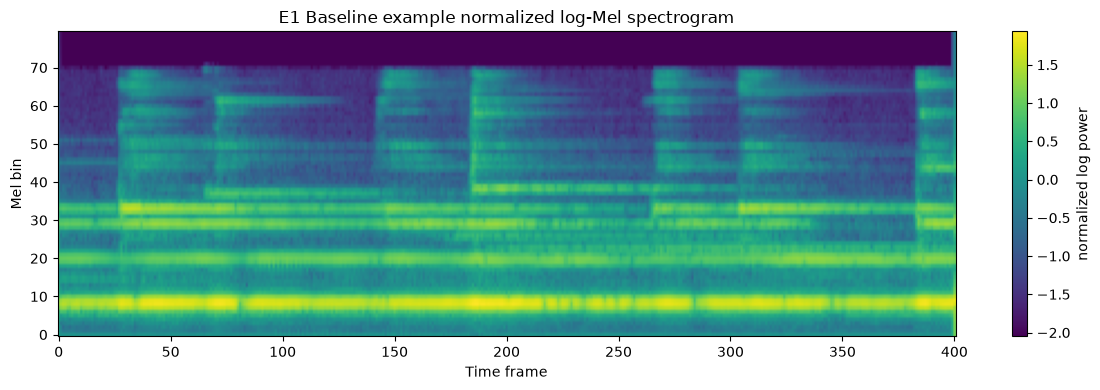

In [11]:
# 10. Visual sanity check for the GPU input representation

sample_row=train_run_df.iloc[0]

sample_path=audio_path_from_row(
    sample_row,
    PROJECT_ROOT
)

sample_wave=cpu_prepare_waveform(
    sample_path,
    sample_rate=SAMPLE_RATE,
    segment_seconds=SEGMENT_SECONDS,
    training=False
)

sample_batch=sample_wave.unsqueeze(0).to(
    DEVICE,
    non_blocking=True
)

with torch.no_grad():
    sample_logmel=gpu_logmel(
        sample_batch
    )

sample_logmel=normalize_log_mel(
    sample_logmel,
    MEL_MEAN,
    MEL_STD
)

sample_logmel=sample_logmel[0].cpu().numpy()

print("Audio:",sample_path.name)
print("Type:",sample_row["type"])
print("Label:",sample_row["label"])
print("Generator:",sample_row["generator"])
print("Waveform shape:",sample_wave.shape)
print("Log-Mel shape:",sample_logmel.shape)

plt.figure(figsize=(12,4))
plt.imshow(
    sample_logmel,
    origin="lower",
    aspect="auto"
)
plt.title("E1 Baseline example normalized log-Mel spectrogram")
plt.xlabel("Time frame")
plt.ylabel("Mel bin")
plt.colorbar(label="normalized log power")
plt.tight_layout()
plt.show()


In [12]:
# 11. Build the training and development DataLoaders

train_loader=make_waveform_loader(train_run_df,True)

train_eval_loader=make_waveform_loader(train_run_df,False)

dev_loader=make_waveform_loader(dev_run_df,False)

print("Training batches:",len(train_loader))
print("Training evaluation batches:",len(train_eval_loader))
print("Development batches:",len(dev_loader))

Training batches: 1875
Training evaluation batches: 1875
Development batches: 705


In [13]:
# 12. Build MobileNetV3-Small for one-channel spectrogram input

class MobileNetV3SmallAudio(nn.Module):
    def __init__(self,num_classes=2):
        super().__init__()

        self.backbone=mobilenet_v3_small(
            weights=None,
            num_classes=num_classes
        )

        # Replace the RGB input layer with a single-channel input layer
        old_conv=self.backbone.features[0][0]

        new_conv=nn.Conv2d(
            in_channels=1,
            out_channels=old_conv.out_channels,
            kernel_size=old_conv.kernel_size,
            stride=old_conv.stride,
            padding=old_conv.padding,
            dilation=old_conv.dilation,
            groups=old_conv.groups,
            bias=False
        )

        self.backbone.features[0][0]=new_conv

    def forward(self,x):
        return self.backbone(x)


model=MobileNetV3SmallAudio(num_classes=2).to(DEVICE)

total_params=sum(p.numel() for p in model.parameters())
trainable_params=sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")


Total parameters: 1,519,618
Trainable parameters: 1,519,618


# 13. Loss function and optimizer

The training labels are slightly imbalanced, so E1 uses class-weighted cross entropy.

The optimizer is AdamW with a small weight decay.

A `ReduceLROnPlateau` scheduler reduces the learning rate when development Macro-F1 stops improving.

The development set is used for model selection; the evaluation set is not used to choose the model.


In [14]:
# 13. Loss and optimizer (Class-Weighted Cross-Entropy)

# Compute inverse frequency class weights to balance 44,000 fake vs 16,000 real training clips
class_counts = train_run_df["label"].map(LABEL_MAP).value_counts().sort_index()
total_samples = len(train_run_df)

# Balanced weight formula: w_c = N / (C * N_c)
class_weights = total_samples / (2.0 * class_counts.values.astype(np.float32))
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Learning rate scheduler that adapts during extended 35-epoch training (no verbose argument)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3,
    min_lr=1e-6
)

print(f"Training Class Counts (0=Real, 1=Fake): {dict(class_counts)}")
print(f"Class Weights (Real, Fake)            : {class_weights}")
print(f"Loss Function                          : CrossEntropyLoss(weight={class_weights_tensor.cpu().numpy()})")

Training Class Counts (0=Real, 1=Fake): {0: np.int64(16000), 1: np.int64(44000)}
Class Weights (Real, Fake)            : [1.875     0.6818182]
Loss Function                          : CrossEntropyLoss(weight=[1.875     0.6818182])


# 14. Evaluation metrics

The main E1 metrics are:

### Macro-F1

Macro-F1 calculates F1 separately for real and fake classes and then averages them. This prevents the larger class from dominating the summary score.

### AUROC

AUROC measures how well the model ranks fake and real examples across decision thresholds.

### EER

Equal Error Rate is calculated from the ROC curve by finding the point where false-positive and false-negative rates are approximately equal.

Accuracy is also recorded, but it is not the primary metric for comparing the detector.


In [15]:
# 14. Evaluation metrics (compute_eer, calculate_metrics, waveform_batch_to_features, run_evaluation)

def compute_eer(y_true, scores):
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    if len(np.unique(y_true)) < 2:
        return float("nan"), float("nan")
    fpr, tpr, thresholds = roc_curve(y_true, scores)
    fnr = 1.0 - tpr
    index = np.nanargmin(np.abs(fpr - fnr))
    eer = float((fpr[index] + fnr[index]) / 2.0)
    threshold = float(thresholds[index])
    return eer, threshold

def calculate_metrics(y_true, scores, threshold=0.5):
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores).astype(float)
    if len(y_true) == 0:
        raise ValueError("Cannot calculate metrics on an empty dataset.")
    predictions = (scores >= threshold).astype(int)
    metrics = {
        "macro_f1": float(f1_score(y_true, predictions, average="macro", zero_division=0)),
        "accuracy": float(accuracy_score(y_true, predictions)),
        "auroc": float("nan")
    }
    if len(np.unique(y_true)) == 2:
        metrics["auroc"] = float(roc_auc_score(y_true, scores))
    eer, eer_threshold = compute_eer(y_true, scores)
    metrics["eer"] = eer
    metrics["eer_threshold"] = eer_threshold
    return metrics, predictions

@torch.no_grad()
def waveform_batch_to_features(waveforms):
    waveforms = waveforms.to(DEVICE, non_blocking=True)
    log_mel = gpu_logmel(waveforms)
    log_mel = normalize_log_mel(log_mel, MEL_MEAN, MEL_STD)
    return log_mel.unsqueeze(1)

@torch.no_grad()
def run_evaluation(model, loader, criterion=None, description="Evaluating"):
    model.eval()
    total_loss = 0.0
    total_items = 0
    all_labels = []
    all_scores = []
    all_file_ids = []
    for waveforms, y, file_ids in tqdm(loader, desc=description, leave=False):
        y = y.to(DEVICE, non_blocking=True)
        x = waveform_batch_to_features(waveforms)
        with autocast_context():
            logits = model(x)
            if criterion is not None:
                loss = criterion(logits, y)
        if criterion is not None:
            total_loss += float(loss.item()) * x.size(0)
        scores = torch.softmax(logits.float(), dim=1)[:, 1]
        all_labels.extend(y.cpu().numpy().tolist())
        all_scores.extend(scores.float().cpu().numpy().tolist())
        all_file_ids.extend(list(file_ids))
        total_items += x.size(0)
    avg_loss = total_loss / max(total_items, 1)
    metrics, predictions = calculate_metrics(all_labels, all_scores)
    metrics["loss"] = avg_loss
    return metrics, np.asarray(all_labels), np.asarray(all_scores), predictions, all_file_ids


## GPU training and GPU feature extraction

CPU DataLoader workers handle audio decoding, resampling and crop/repeat-padding. Batched STFT, Mel extraction, log compression and normalization run on the GPU when CUDA is available.

In [16]:
# 15. Mixed-precision training setup

amp_enabled=DEVICE.type=="cuda"

scaler=torch.amp.GradScaler(
    "cuda",
    enabled=amp_enabled
)

def autocast_context():
    return torch.amp.autocast(
        device_type=DEVICE.type,
        dtype=torch.float16,
        enabled=amp_enabled
    )

# 16. Training loop

The model is trained on the training partition and evaluated on the development partition after every epoch.

The best checkpoint is selected using **development Macro-F1**.

Training runs for the full 35 epochs without early stopping, preserving the best checkpoint achieved on development Macro-F1.

The evaluation partition is not used during model selection.

In [17]:
# 16. Train one epoch with gradient clipping

def train_one_epoch(model, loader):
    model.train()
    running_loss = 0.0
    correct = 0
    total_items = 0
    grad_norms = []

    progress = tqdm(loader, desc="Training", leave=False)

    for waveforms, y, _ in progress:
        y = y.to(DEVICE, non_blocking=True)
        x = waveform_batch_to_features(waveforms)

        optimizer.zero_grad(set_to_none=True)

        with autocast_context():
            logits = model(x)
            loss = criterion(logits, y)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)                                              # 1. unscale first
        gn = torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)  # 2. then clip
        if torch.isfinite(gn):
            grad_norms.append(float(gn))
        scaler.step(optimizer)                                                  # 3. step skips inf/nan automatically
        scaler.update()

        predictions = torch.argmax(logits, dim=1)
        correct += (predictions == y).sum().item()
        running_loss += float(loss.item()) * x.size(0)
        total_items += x.size(0)

        progress.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = running_loss / max(total_items, 1)
    train_accuracy = correct / max(total_items, 1)
    gn_med = float(np.median(grad_norms)) if grad_norms else 0.0
    gn_p99 = float(np.percentile(grad_norms, 99)) if grad_norms else 0.0

    return train_loss, train_accuracy, gn_med, gn_p99

In [18]:
# 17. Train E1 Baseline to Convergence (35 Epochs, Multi-Seed Protocol)

history = []
best_dev_f1 = -np.inf
best_epoch = -1
epochs_without_improvement = 0

best_checkpoint_path = CHECKPOINT_DIR / f"E1_MobileNetV3Small_ATADD_best_{SEED_TAG}.pt"
history_path = EXPERIMENT_DIR / f"E1_ATADD_training_history_{SEED_TAG}.csv"

print(f"Starting E1 Baseline ({SEED_TAG}, seed={SEED}) training for {EPOCHS} epochs (Early stopping disabled, Max Grad Norm: {MAX_GRAD_NORM})...")

for epoch in range(1, EPOCHS + 1):
    start_time = time.time()
    train_loss, train_accuracy, gn_med, gn_p99 = train_one_epoch(model, train_loader)
    dev_metrics, dev_y, dev_scores, dev_preds, dev_ids = run_evaluation(model, dev_loader, criterion)

    # Step scheduler based on Dev Macro-F1
    scheduler.step(dev_metrics["macro_f1"])
    epoch_time = time.time() - start_time

    row = {
        "epoch": epoch,
        "train_loss": float(train_loss),
        "train_accuracy": float(train_accuracy),
        "grad_norm_median": float(gn_med),
        "grad_norm_p99": float(gn_p99),
        "dev_loss": float(dev_metrics["loss"]),
        "dev_accuracy": float(dev_metrics["accuracy"]),
        "dev_macro_f1": float(dev_metrics["macro_f1"]),
        "dev_auroc": float(dev_metrics["auroc"]),
        "dev_eer": float(dev_metrics["eer"]),
        "lr": float(optimizer.param_groups[0]["lr"]),
        "epoch_seconds": float(epoch_time),
        "seed_tag": SEED_TAG,
        "seed": SEED
    }
    history.append(row)

    history_df = pd.DataFrame(history)
    history_df.to_csv(history_path, index=False)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} [{epoch_time:.1f}s] | "
        f"Train Loss: {train_loss:.4f} Acc: {train_accuracy:.4f} | "
        f"GN(med/p99): {gn_med:.2f}/{gn_p99:.2f} | "
        f"Dev Loss: {dev_metrics['loss']:.4f} Acc: {dev_metrics['accuracy']:.4f} "
        f"F1: {dev_metrics['macro_f1']:.4f} AUROC: {dev_metrics['auroc']:.4f} EER: {dev_metrics['eer']*100:.2f}% | "
        f"LR: {optimizer.param_groups[0]['lr']:.2e}"
    )

    if dev_metrics["macro_f1"] > best_dev_f1:
        best_dev_f1 = dev_metrics["macro_f1"]
        best_epoch = epoch
        epochs_without_improvement = 0
        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "dev_metrics": dev_metrics,
                "seed_tag": SEED_TAG,
                "seed": SEED,
                "max_grad_norm": MAX_GRAD_NORM,
                "class_weights": class_weights.tolist()
            },
            best_checkpoint_path
        )
        print(f"  -> Best Dev Macro-F1: {best_dev_f1:.6f} saved to {best_checkpoint_path.name}")
    else:
        epochs_without_improvement += 1
        print(f"  -> No improvement for {epochs_without_improvement} epoch(s)")

print(f"\nTraining complete! Best checkpoint: {best_checkpoint_path} (Epoch {best_epoch}, Dev Macro-F1: {best_dev_f1:.6f})")

Starting E1 Baseline (seed2, seed=1337) training for 25 epochs (Early stopping disabled, Max Grad Norm: 5.0)...


Epoch 01/25 [132.6s] | Train Loss: 0.3128 Acc: 0.8616 | GN(med/p99): 3.61/19.30 | Dev Loss: 1.3480 Acc: 0.6965 F1: 0.6300 AUROC: 0.6574 EER: 37.65% | LR: 1.00e-03
  -> Best Dev Macro-F1: 0.629986 saved to E1_MobileNetV3Small_ATADD_best_seed2.pt


Epoch 02/25 [122.5s] | Train Loss: 0.1534 Acc: 0.9401 | GN(med/p99): 3.27/20.75 | Dev Loss: 0.8523 Acc: 0.6190 F1: 0.6140 AUROC: 0.8054 EER: 28.29% | LR: 1.00e-03
  -> No improvement for 1 epoch(s)


Epoch 03/25 [121.0s] | Train Loss: 0.1057 Acc: 0.9614 | GN(med/p99): 2.55/17.40 | Dev Loss: 0.8238 Acc: 0.6924 F1: 0.6841 AUROC: 0.8801 EER: 20.07% | LR: 1.00e-03
  -> Best Dev Macro-F1: 0.684111 saved to E1_MobileNetV3Small_ATADD_best_seed2.pt


Epoch 04/25 [121.2s] | Train Loss: 0.0840 Acc: 0.9688 | GN(med/p99): 2.12/15.24 | Dev Loss: 1.4855 Acc: 0.6015 F1: 0.5973 AUROC: 0.8095 EER: 26.52% | LR: 1.00e-03
  -> No improvement for 1 epoch(s)


...

Epoch 21/25 [120.8s] | Train Loss: 0.0049 Acc: 0.9984 | GN(med/p99): 0.01/10.11 | Dev Loss: 2.0969 Acc: 0.6766 F1: 0.6688 AUROC: 0.8731 EER: 20.24% | LR: 6.25e-05
  -> No improvement for 12 epoch(s)


Epoch 22/25 [118.0s] | Train Loss: 0.0051 Acc: 0.9986 | GN(med/p99): 0.01/9.38 | Dev Loss: 2.1293 Acc: 0.6882 F1: 0.6792 AUROC: 0.8705 EER: 20.13% | LR: 6.25e-05
  -> No improvement for 13 epoch(s)


Epoch 23/25 [122.0s] | Train Loss: 0.0040 Acc: 0.9987 | GN(med/p99): 0.01/8.15 | Dev Loss: 2.6231 Acc: 0.6594 F1: 0.6539 AUROC: 0.8766 EER: 19.60% | LR: 6.25e-05
  -> No improvement for 14 epoch(s)


Epoch 24/25 [117.5s] | Train Loss: 0.0037 Acc: 0.9988 | GN(med/p99): 0.00/7.91 | Dev Loss: 2.9073 Acc: 0.6327 F1: 0.6290 AUROC: 0.8692 EER: 20.16% | LR: 6.25e-05
  -> No improvement for 15 epoch(s)


Epoch 25/25 [123.2s] | Train Loss: 0.0035 Acc: 0.9990 | GN(med/p99): 0.00/7.64 | Dev Loss: 3.3508 Acc: 0.6252 F1: 0.6216 AUROC: 0.8578 EER: 21.25% | LR: 3.13e-05
  -> No improvement for 16 epoch(s)

Training complete! Best checkpoint: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/checkpoints/reworked/E1/E1_MobileNetV3Small_ATADD_best_seed2.pt (Epoch 9, Dev Macro-F1: 0.690911)


## Training curves

The training curves provide a quick way to identify:

- underfitting
- overfitting
- unstable optimization
- whether the development performance has stopped improving

These plots are saved under `results/figures/` for the project record.


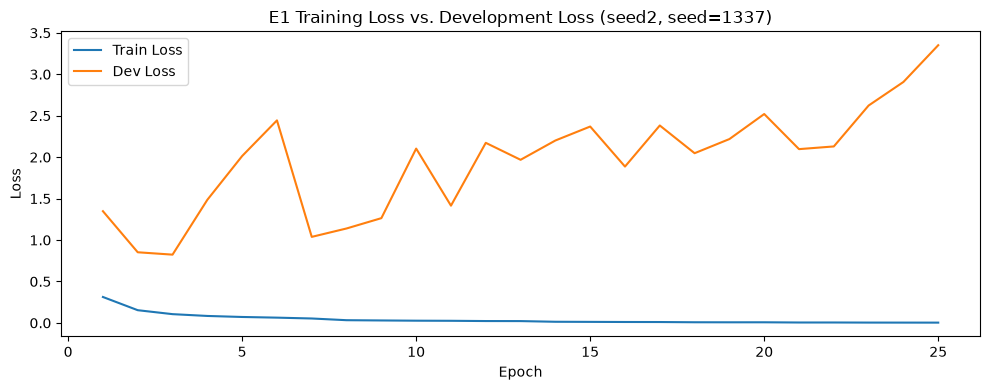

Saved training curves to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/results/figures/reworked/E1/E1_ATADD_training_curves_seed2.png


In [19]:
# 18. Plot and save training curves

plt.figure(figsize=(10, 4))
plt.plot(history_df["epoch"], history_df["train_loss"], label="Train Loss")
plt.plot(history_df["epoch"], history_df["dev_loss"], label="Dev Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(f"E1 Training Loss vs. Development Loss ({SEED_TAG}, seed={SEED})")
plt.legend()
plt.tight_layout()

curves_path = RESULT_FIGURE_DIR / f"E1_ATADD_training_curves_{SEED_TAG}.png"
plt.savefig(curves_path, dpi=200)
plt.show()

print("Saved training curves to:", curves_path)


# 19. Final development evaluation

After training, we reload the checkpoint with the best development Macro-F1.

All reported development metrics below therefore correspond to the selected E1 checkpoint rather than simply the final training epoch.


In [20]:
checkpoint=torch.load(best_checkpoint_path,map_location=DEVICE,weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])

print(f"Loaded checkpoint for {SEED_TAG} from epoch:",checkpoint["epoch"])
print(f"Best development Macro-F1 ({SEED_TAG}):",checkpoint["dev_metrics"]["macro_f1"])

Loaded checkpoint for seed2 from epoch: 9
Best development Macro-F1 (seed2): 0.6909111613948411


## Development-set results

These are the metrics we use to understand how well the clean E1 baseline learned the real/fake classification task.

The development predictions are also saved so that later analysis can inspect individual recordings.


In [21]:
# 20. Final development-set evaluation & Decision-Threshold Calibration

val_metrics_05, val_y, val_scores, val_preds_05, val_ids = run_evaluation(model, dev_loader, criterion)

# Sweep decision thresholds on the validation set to find optimal threshold theta*
candidate_thresholds = np.linspace(0.01, 0.99, 99)
sweep_records = []
best_dev_thresh = 0.50
best_dev_macro_f1 = -1.0

for t in candidate_thresholds:
    preds_t = (val_scores >= t).astype(int)
    f1_t = f1_score(val_y, preds_t, average="macro", zero_division=0)
    acc_t = accuracy_score(val_y, preds_t)
    bacc_t = balanced_accuracy_score(val_y, preds_t)
    if f1_t > best_dev_macro_f1:
        best_dev_macro_f1 = f1_t
        best_dev_thresh = float(t)
    sweep_records.append({
        "threshold": float(t),
        "macro_f1": float(f1_t),
        "accuracy": float(acc_t),
        "balanced_accuracy": float(bacc_t)
    })

dev_sweep_df = pd.DataFrame(sweep_records)
dev_sweep_path = EXPERIMENT_DIR / f"E1_ATADD_dev_threshold_sweep_{SEED_TAG}.csv"
dev_sweep_df.to_csv(dev_sweep_path, index=False)

# Compute metrics at the calibrated threshold
val_metrics_opt, val_preds_opt = calculate_metrics(val_y, val_scores, threshold=best_dev_thresh)
val_metrics_opt["loss"] = val_metrics_05["loss"]

print(f"=== E1 VALIDATION RESULTS ({SEED_TAG}) ===")
print(f"Fixed Default Threshold (theta = 0.50):")
print(f"  Macro-F1          : {val_metrics_05['macro_f1']:.6f}")
print(f"  Accuracy          : {val_metrics_05['accuracy']:.6f}")
print(f"  AUROC             : {val_metrics_05['auroc']:.6f}")
print(f"  EER               : {val_metrics_05['eer']*100:.2f}% (threshold={val_metrics_05['eer_threshold']:.4f})")
print(f"\nDev-Calibrated Threshold (theta* = {best_dev_thresh:.4f}):")
print(f"  Calibrated Macro-F1: {val_metrics_opt['macro_f1']:.6f} (Delta: {val_metrics_opt['macro_f1'] - val_metrics_05['macro_f1']:+.6f})")
print(f"  Calibrated Accuracy: {val_metrics_opt['accuracy']:.6f}")

val_metrics_all = {
    "fixed_0.5": val_metrics_05,
    "calibrated_dev": val_metrics_opt,
    "optimal_dev_threshold": best_dev_thresh
}

val_metrics_path = EXPERIMENT_DIR / f"E1_ATADD_validation_metrics_{SEED_TAG}.json"
with open(val_metrics_path, "w", encoding="utf-8") as f:
    json.dump(val_metrics_all, f, indent=2)

print("Saved validation metrics to:", val_metrics_path)

=== E1 VALIDATION RESULTS (seed2) ===
Fixed Default Threshold (theta = 0.50):
  Macro-F1          : 0.690911
  Accuracy          : 0.698926
  AUROC             : 0.897565
  EER               : 16.97% (threshold=0.0209)

Dev-Calibrated Threshold (theta* = 0.0100):
  Calibrated Macro-F1: 0.819759 (Delta: +0.128848)
  Calibrated Accuracy: 0.846246
Saved validation metrics to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E1/E1_ATADD_validation_metrics_seed2.json


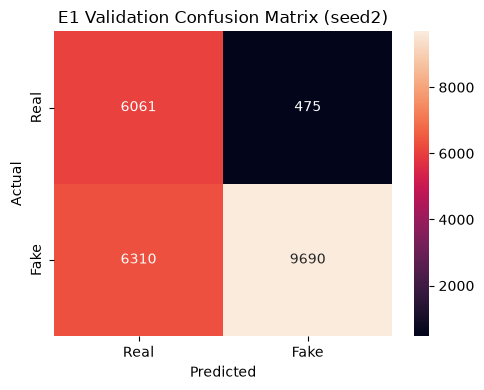

Saved: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/results/figures/reworked/E1/E1_ATADD_validation_confusion_matrix_seed2.png


In [22]:
# 21. Validation confusion matrix

cm = confusion_matrix(val_y, val_preds_05)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Real", "Fake"],
    yticklabels=["Real", "Fake"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"E1 Validation Confusion Matrix ({SEED_TAG})")
plt.tight_layout()

val_cm_path = RESULT_FIGURE_DIR / f"E1_ATADD_validation_confusion_matrix_{SEED_TAG}.png"
plt.savefig(val_cm_path, dpi=200)
plt.show()

print("Saved:", val_cm_path)


## Save development predictions

Saving the individual prediction scores is useful later when comparing E1 with E2/E3 or investigating difficult examples.

The file contains the model's fake score, predicted class and ground-truth label for each development recording.


In [23]:
# 22. Save validation predictions for later analysis

val_output = pd.DataFrame({
    "file_id": val_ids,
    "label": val_y,
    "spoof_score": val_scores,
    "prediction_05": (val_scores >= 0.5).astype(int),
    "prediction_opt": (val_scores >= best_dev_thresh).astype(int),
    "seed_tag": SEED_TAG,
    "seed": SEED
})

val_output_path = EXPERIMENT_DIR / f"E1_ATADD_val_predictions_{SEED_TAG}.csv"
val_output.to_csv(val_output_path, index=False)
print("Saved validation predictions to:", val_output_path)

Saved validation predictions to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E1/E1_ATADD_val_predictions_seed2.csv


# 23. Official evaluation inference

The official evaluation partition is processed only after the E1 checkpoint has been selected using the development set.

If evaluation labels are available, the notebook calculates the same metrics used on the development set.

If labels are not available, it saves prediction scores without inventing evaluation metrics.


In [24]:
# 23. Prepare the official evaluation DataLoader

eval_scores=np.asarray([])
eval_labels=np.asarray([])
eval_ids=[]
eval_analysis=pd.DataFrame()

if len(eval_run_df):
    eval_loader=make_waveform_loader(
        eval_run_df,
        False
    )
else:
    eval_loader=None

print(
    "Evaluation loader ready:",
    eval_loader is not None
)


Evaluation loader ready: True


In [26]:
# 24. Run official evaluation inference (Dual Thresholds: Fixed 0.5 & Dev-Calibrated theta*)

if len(eval_run_df):
    model.eval()
    eval_scores = []
    eval_labels = []
    eval_ids = []

    with torch.no_grad():
        for waveforms, y, file_ids in tqdm(eval_loader, desc=f"Official evaluation ({SEED_TAG})"):
            y = y.to(DEVICE, non_blocking=True)
            x = waveform_batch_to_features(waveforms)
            with autocast_context():
                logits = model(x)
            scores = torch.softmax(logits.float(), dim=1)[:, 1]
            eval_scores.extend(scores.float().cpu().numpy().tolist())
            eval_labels.extend(y.cpu().numpy().tolist())
            eval_ids.extend(list(file_ids))

    eval_scores = np.asarray(eval_scores)
    eval_labels = np.asarray(eval_labels)

    # Compute predictions at BOTH thresholds
    eval_predictions_05 = (eval_scores >= 0.5).astype(int)
    eval_predictions_opt = (eval_scores >= best_dev_thresh).astype(int)

    eval_output = pd.DataFrame({
        "file_id": eval_ids,
        "label": eval_labels,
        "spoof_score": eval_scores,
        "prediction": eval_predictions_05,        # Default 0.5
        "prediction_05": eval_predictions_05,     # Explicit 0.5
        "prediction_opt": eval_predictions_opt,   # Dev-selected theta*
        "seed_tag": SEED_TAG,
        "seed": SEED
    })

    eval_output_path = EXPERIMENT_DIR / f"E1_ATADD_eval_predictions_{SEED_TAG}.csv"
    eval_output.to_csv(eval_output_path, index=False)
    print("Saved evaluation predictions to:", eval_output_path)

    if len(np.unique(eval_labels)) == 2:
        eval_metrics_05, _ = calculate_metrics(eval_labels, eval_scores, threshold=0.5)
        eval_metrics_opt, _ = calculate_metrics(eval_labels, eval_scores, threshold=best_dev_thresh)

        print(f"\n=== OFFICIAL AT-ADD EVALUATION RESULTS ({SEED_TAG}) ===")
        print(f"--- 1. Default Threshold (theta = 0.50) ---")
        for k, v in eval_metrics_05.items():
            print(f"  {k:<16}: {v:.6f}")

        print(f"\n--- 2. Dev-Calibrated Threshold (theta* = {best_dev_thresh:.4f}) ---")
        for k, v in eval_metrics_opt.items():
            print(f"  {k:<16}: {v:.6f}")

        eval_comparison_summary = {
            "fixed_threshold_0.5": eval_metrics_05,
            "dev_calibrated_threshold": eval_metrics_opt,
            "calibrated_threshold_value": best_dev_thresh
        }

        eval_metrics_path = EXPERIMENT_DIR / f"E1_ATADD_eval_metrics_{SEED_TAG}.json"
        with open(eval_metrics_path, "w", encoding="utf-8") as f:
            json.dump(eval_comparison_summary, f, indent=2)
        print("Saved dual-threshold metrics to:", eval_metrics_path)
    else:
        print("\nEvaluation labels do not contain both classes.")
else:
    print("No evaluation manifest was found.")

Official evaluation (seed2): 100%|██████████| 1385/1385 [00:55<00:00, 24.79it/s]

Saved evaluation predictions to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E1/E1_ATADD_eval_predictions_seed2.csv

=== OFFICIAL AT-ADD EVALUATION RESULTS (seed2) ===
--- 1. Default Threshold (theta = 0.50) ---
  macro_f1        : 0.567925
  accuracy        : 0.616135
  auroc           : 0.879589
  eer             : 0.204158
  eer_threshold   : 0.013637

--- 2. Dev-Calibrated Threshold (theta* = 0.0100) ---
  macro_f1        : 0.709694
  accuracy        : 0.806408
  auroc           : 0.879589
  eer             : 0.204158
  eer_threshold   : 0.013637
Saved dual-threshold metrics to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E1/E1_ATADD_eval_metrics_seed2.json


DUAL-THRESHOLD GENERALIZATION AUDIT (seed2)
Thresholds: Default theta=0.50  vs.  Dev-Calibrated theta*=0.0100

[A] Per-Type Domain Breakdown (4 Domains)
----------------------------------------------------------------------


,Domain,Total Samples,Real Samples,Fake Samples,Macro-F1 (0.50),Macro-F1 (theta*),Delta F1,AUROC,EER (%)
0,Speech,27000,2000,25000,0.542808,0.680102,0.137294,0.903043,17.998000
1,Sound,6000,2000,4000,0.615265,0.749184,0.133919,0.856586,23.550000
2,Singing,6753,2000,4753,0.513779,0.747310,0.233532,0.897236,18.153477
3,Music,4536,536,4000,0.411211,0.496263,0.085052,0.646006,39.925187


Type-Averaged Macro-F1 at theta=0.50   : 0.520766
Type-Averaged Macro-F1 at theta*=0.01: 0.668215 (Delta: +0.147449)
Saved domain breakdown to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E1/E1_ATADD_eval_type_results_seed2.csv

[B] Per-Generator Breakdown on 38 Unseen Fake Generators
----------------------------------------------------------------------


,Generator,Domain,Samples,Recall (0.50),Recall (theta*),Delta Recall,Mean Spoof Score
26,SSM-TTM,music,1000,0.025000,0.201000,0.176000,0.036688
0,ACE-Step,music,1000,0.120000,0.370000,0.250000,0.126312
1,Auffusion,sound,1000,0.168000,0.536000,0.368000,0.186229
2,BigVGAN,speech,1000,0.230000,0.549000,0.319000,0.242959
28,So-VITS-SVC-FSD,singing,1000,0.213000,0.554000,0.341000,0.228645
25,RVC-FSD,singing,753,0.217795,0.575033,0.357238,0.228015
17,KNN-SVC,singing,1000,0.272000,0.651000,0.379000,0.278574
23,OpenVoice2,speech,1000,0.365000,0.674000,0.309000,0.370150
33,StyleTTS2,speech,1000,0.399000,0.683000,0.284000,0.407060
16,IndexTTS2,speech,1000,0.391000,0.698000,0.307000,0.400110


... and 23 more generators.
Saved generator breakdown to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E1/E1_ATADD_eval_generator_results_seed2.csv

[C] Real Audio: Seen vs. Unseen Source Breakdown
----------------------------------------------------------------------


,Source Category,Clips,Real Acc (0.50),False Alarm (0.50),Real Acc (theta*),False Alarm (theta*),Mean Spoof Score
0,Seen Source,4864,97.02%,2.98%,83.16%,16.84%,0.039940
1,Unseen Source,1672,91.39%,8.61%,61.66%,38.34%,0.102662


Saved real source breakdown to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E1/eval_real_source_breakdown_seed2.csv


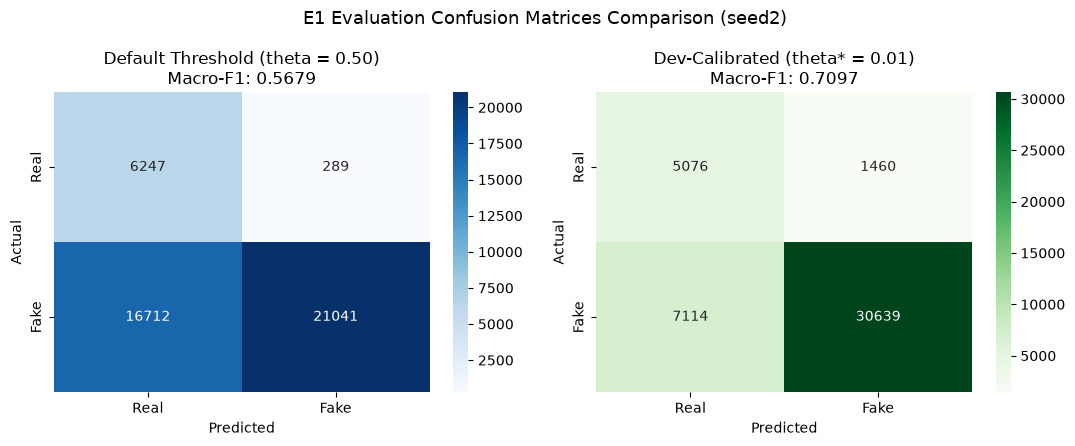

Saved dual confusion matrix figure to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/results/figures/reworked/E1/E1_ATADD_eval_confusion_matrix_seed2.png


In [27]:
# 24.5. Dual-Threshold Generalization Analysis: Per-Type, Per-Generator, & Seen vs Unseen Real Sources

if len(eval_run_df) and len(eval_scores):
    eval_analysis = eval_run_df[
        [
            "file_id",
            "type",
            "label",
            "generator",
            "source"
        ]
    ].copy()

    eval_analysis["label_id"] = eval_analysis["label"].map(LABEL_MAP)
    eval_analysis["spoof_score"] = eval_scores
    eval_analysis["prediction_05"] = (eval_scores >= 0.5).astype(int)
    eval_analysis["prediction_opt"] = (eval_scores >= best_dev_thresh).astype(int)
    eval_analysis["prediction"] = eval_analysis["prediction_05"]

    print("======================================================================")
    print(f"DUAL-THRESHOLD GENERALIZATION AUDIT ({SEED_TAG})")
    print(f"Thresholds: Default theta=0.50  vs.  Dev-Calibrated theta*={best_dev_thresh:.4f}")
    print("======================================================================")

    # -------------------------------------------------------------------------
    # A. Per-Type Domain Breakdown at BOTH Thresholds
    # -------------------------------------------------------------------------
    print(f"\n[A] Per-Type Domain Breakdown (4 Domains)")
    print("-" * 70)
    type_results = []
    for audio_type in ["speech", "sound", "singing", "music"]:
        subset = eval_analysis[eval_analysis["type"] == audio_type]
        if len(subset) == 0:
            continue
        y_true = subset["label_id"].to_numpy()
        scores = subset["spoof_score"].to_numpy()
        if len(np.unique(y_true)) < 2:
            continue

        metrics_05, _ = calculate_metrics(y_true, scores, threshold=0.5)
        metrics_opt, _ = calculate_metrics(y_true, scores, threshold=best_dev_thresh)

        type_results.append({
            "Domain": audio_type.capitalize(),
            "Total Samples": len(subset),
            "Real Samples": int((y_true == 0).sum()),
            "Fake Samples": int((y_true == 1).sum()),
            "Macro-F1 (0.50)": metrics_05["macro_f1"],
            "Macro-F1 (theta*)": metrics_opt["macro_f1"],
            "Delta F1": metrics_opt["macro_f1"] - metrics_05["macro_f1"],
            "AUROC": metrics_05["auroc"],
            "EER (%)": metrics_05["eer"] * 100.0
        })

    type_results_df = pd.DataFrame(type_results)
    display(type_results_df)

    type_avg_f1_05 = type_results_df["Macro-F1 (0.50)"].mean()
    type_avg_f1_opt = type_results_df["Macro-F1 (theta*)"].mean()
    print(f"Type-Averaged Macro-F1 at theta=0.50   : {type_avg_f1_05:.6f}")
    print(f"Type-Averaged Macro-F1 at theta*={best_dev_thresh:.2f}: {type_avg_f1_opt:.6f} (Delta: {type_avg_f1_opt - type_avg_f1_05:+.6f})")

    type_results_path = EXPERIMENT_DIR / f"E1_ATADD_eval_type_results_{SEED_TAG}.csv"
    type_results_df.to_csv(type_results_path, index=False)
    table_path = RESULT_TABLE_DIR / f"eval_domain_summary_{SEED_TAG}.csv"
    type_results_df.to_csv(table_path, index=False)
    print("Saved domain breakdown to:", type_results_path)

    # -------------------------------------------------------------------------
    # B. Per-Generator Breakdown on Fake Samples at BOTH Thresholds
    # -------------------------------------------------------------------------
    print(f"\n[B] Per-Generator Breakdown on 38 Unseen Fake Generators")
    print("-" * 70)
    fake_eval = eval_analysis[eval_analysis["label"] == "fake"]
    generator_results = []

    for generator, group in fake_eval.groupby("generator"):
        if generator == "-" or pd.isna(generator):
            continue
        scores = group["spoof_score"].to_numpy()
        preds_05 = group["prediction_05"].to_numpy()
        preds_opt = group["prediction_opt"].to_numpy()

        det_05 = int((preds_05 == 1).sum())
        det_opt = int((preds_opt == 1).sum())
        total = len(group)

        generator_results.append({
            "Generator": generator,
            "Domain": group["type"].mode().iloc[0],
            "Samples": total,
            "Recall (0.50)": det_05 / total,
            "Recall (theta*)": det_opt / total,
            "Delta Recall": (det_opt - det_05) / total,
            "Mean Spoof Score": float(scores.mean())
        })

    generator_results_df = pd.DataFrame(generator_results).sort_values("Recall (theta*)")
    display(generator_results_df.head(15))
    print(f"... and {len(generator_results_df) - 15} more generators.")

    gen_path = EXPERIMENT_DIR / f"E1_ATADD_eval_generator_results_{SEED_TAG}.csv"
    generator_results_df.to_csv(gen_path, index=False)
    print("Saved generator breakdown to:", gen_path)

    # -------------------------------------------------------------------------
    # C. Real Audio: Seen vs. Unseen Real Source Breakdown at BOTH Thresholds
    # -------------------------------------------------------------------------
    print(f"\n[C] Real Audio: Seen vs. Unseen Source Breakdown")
    print("-" * 70)
    seen_sources = set(train_df.loc[train_df["label"] == "real", "source"]) | set(dev_df.loc[dev_df["label"] == "real", "source"])
    real_eval = eval_analysis[eval_analysis["label"] == "real"].copy()
    real_eval["source_category"] = real_eval["source"].apply(
        lambda s: "Seen Source" if s in seen_sources else "Unseen Source"
    )

    real_source_results = []
    for cat, group in real_eval.groupby("source_category"):
        total = len(group)
        correct_05 = int((group["prediction_05"] == 0).sum())
        fp_05 = int((group["prediction_05"] == 1).sum())

        correct_opt = int((group["prediction_opt"] == 0).sum())
        fp_opt = int((group["prediction_opt"] == 1).sum())

        real_source_results.append({
            "Source Category": cat,
            "Clips": total,
            "Real Acc (0.50)": f"{correct_05 / total * 100:.2f}%",
            "False Alarm (0.50)": f"{fp_05 / total * 100:.2f}%",
            "Real Acc (theta*)": f"{correct_opt / total * 100:.2f}%",
            "False Alarm (theta*)": f"{fp_opt / total * 100:.2f}%",
            "Mean Spoof Score": float(group["spoof_score"].mean())
        })

    real_source_df = pd.DataFrame(real_source_results)
    display(real_source_df)

    real_source_path = EXPERIMENT_DIR / f"eval_real_source_breakdown_{SEED_TAG}.csv"
    real_source_df.to_csv(real_source_path, index=False)
    print("Saved real source breakdown to:", real_source_path)

    # -------------------------------------------------------------------------
    # D. Side-by-Side Confusion Matrices
    # -------------------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

    cm_05 = confusion_matrix(eval_labels, eval_analysis["prediction_05"].to_numpy())
    sns.heatmap(cm_05, annot=True, fmt="d", cmap="Blues", ax=axes[0],
                xticklabels=["Real", "Fake"], yticklabels=["Real", "Fake"])
    axes[0].set_title(f"Default Threshold (theta = 0.50)\nMacro-F1: {eval_metrics_05['macro_f1']:.4f}")
    axes[0].set_xlabel("Predicted")
    axes[0].set_ylabel("Actual")

    cm_opt = confusion_matrix(eval_labels, eval_analysis["prediction_opt"].to_numpy())
    sns.heatmap(cm_opt, annot=True, fmt="d", cmap="Greens", ax=axes[1],
                xticklabels=["Real", "Fake"], yticklabels=["Real", "Fake"])
    axes[1].set_title(f"Dev-Calibrated (theta* = {best_dev_thresh:.2f})\nMacro-F1: {eval_metrics_opt['macro_f1']:.4f}")
    axes[1].set_xlabel("Predicted")
    axes[1].set_ylabel("Actual")

    plt.suptitle(f"E1 Evaluation Confusion Matrices Comparison ({SEED_TAG})", fontsize=13)
    plt.tight_layout()
    eval_cm_path = RESULT_FIGURE_DIR / f"E1_ATADD_eval_confusion_matrix_{SEED_TAG}.png"
    plt.savefig(eval_cm_path, dpi=200)
    plt.show()
    print("Saved dual confusion matrix figure to:", eval_cm_path)
else:
    print("Evaluation analysis is not available.")

In [28]:
# Evaluation failure-case analysis (at both thresholds)

if len(eval_analysis):
    for thresh_tag, col in [("0.50", "prediction_05"), ("calibrated", "prediction_opt")]:
        fn = eval_analysis[
            (eval_analysis["label"].isin(["fake", "spoof"])) &
            (eval_analysis[col] == 0)
        ].copy()
        fp = eval_analysis[
            (eval_analysis["label"].isin(["real", "bonafide"])) &
            (eval_analysis[col] == 1)
        ].copy()

        print(f"Threshold [{thresh_tag}]: False Negatives (Missed Spoofs) = {len(fn):,}, False Positives (False Alarms) = {len(fp):,}")

        failures = pd.concat([
            fn.assign(error_type="false_negative", eval_threshold=thresh_tag),
            fp.assign(error_type="false_positive", eval_threshold=thresh_tag)
        ])

        fail_path = EXPERIMENT_DIR / f"E1_ATADD_eval_failure_cases_{thresh_tag}_{SEED_TAG}.csv"
        failures.to_csv(fail_path, index=False)
        print(f"Saved {thresh_tag} failure cases to: {fail_path}")

    # Backward compatibility file
    default_failures = eval_analysis[
        ((eval_analysis["label"].isin(["fake", "spoof"])) & (eval_analysis["prediction_05"] == 0)) |
        ((eval_analysis["label"].isin(["real", "bonafide"])) & (eval_analysis["prediction_05"] == 1))
    ]
    compat_path = EXPERIMENT_DIR / f"E1_ATADD_eval_failure_cases_{SEED_TAG}.csv"
    default_failures.to_csv(compat_path, index=False)
    print("Saved default failure cases to:", compat_path)
else:
    print("Evaluation analysis is not available.")

Threshold [0.50]: False Negatives (Missed Spoofs) = 16,712, False Positives (False Alarms) = 289
Saved 0.50 failure cases to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E1/E1_ATADD_eval_failure_cases_0.50_seed2.csv
Threshold [calibrated]: False Negatives (Missed Spoofs) = 7,114, False Positives (False Alarms) = 1,460
Saved calibrated failure cases to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E1/E1_ATADD_eval_failure_cases_calibrated_seed2.csv
Saved default failure cases to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E1/E1_ATADD_eval_failure_cases_seed2.csv


### Evaluation analysis note

The AT-ADD generator/type analysis is performed in the previous cell.

No speaker-overlap claim is made here because Track 2 metadata uses `-` for some identity fields by design. The primary generalization criterion for this E1 evaluation is the verified unseen-generator split.

# 25. Save the E1 experiment configuration

The final configuration records the model, preprocessing, dataset preparation version and training settings.

This is important because later changes to preprocessing or model design should produce a new experiment version rather than silently changing the meaning of E1.


In [29]:
# 25. Save the complete E1 Reworked AT-ADD configuration

config = {
    "experiment": f"E1_ATADD_Reworked_{SEED_TAG}",
    "seed_tag": SEED_TAG,
    "seed": SEED,
    "experiment_version": EXPERIMENT_VERSION,
    "input_preprocessing_version": INPUT_PREPROCESSING_VERSION,
    "preprocessing_module": "src/preprocessing/preprocess_atadd_rerun.py",
    "dataset_preparation_version": "AT-ADD_reworked_v1",
    "model": {
        "name": "MobileNetV3-Small",
        "weights": "scratch",
        "input_channels": 1,
        "num_classes": 2,
        "total_parameters": total_params,
        "trainable_parameters": trainable_params
    },
    "dataset": {
        "name": "AT-ADD Track 2 (Speaker-and-Generator-Disjoint)",
        "train_manifest": str(TRAIN_MANIFEST),
        "dev_manifest": str(DEV_MANIFEST),
        "eval_manifest": str(EVAL_MANIFEST),
        "train_samples": len(train_run_df),
        "dev_samples": len(dev_run_df),
        "eval_samples": len(eval_run_df),
        "label_mapping": LABEL_MAP,
        "pairwise_generator_disjoint": True,
        "pairwise_speaker_disjoint": True,
        "pairwise_source_id_disjoint": True
    },
    "audio": {
        "sample_rate": SAMPLE_RATE,
        "segment_seconds": SEGMENT_SECONDS,
        "num_samples": NUM_SAMPLES
    },
    "spectrogram": {
        "n_fft": N_FFT,
        "win_length": WIN_LENGTH,
        "hop_length": HOP_LENGTH,
        "n_mels": N_MELS,
        "window": "hann",
        "power": 2.0,
        "log_epsilon": LOG_EPS,
        "feature_extraction_device": "cuda" if DEVICE.type == "cuda" else "cpu"
    },
    "training": {
        "seed_tag": SEED_TAG,
        "seed": SEED,
        "batch_size": BATCH_SIZE,
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "patience": PATIENCE,
        "max_grad_norm": MAX_GRAD_NORM,
        "loss": "class_weighted_cross_entropy",
        "class_weights": class_weights.tolist(),
        "optimizer": "AdamW",
        "scheduler": "ReduceLROnPlateau(mode=max, patience=3, factor=0.5)",
        "num_workers": NUM_WORKERS,
        "pin_memory": DEVICE.type == "cuda",
        "cudnn_deterministic": True if DEVICE.type == "cuda" else None,
        "cudnn_benchmark": False if DEVICE.type == "cuda" else None
    },
    "threshold_calibration": {
        "default_threshold": 0.50,
        "dev_selected_threshold": best_dev_thresh if "best_dev_thresh" in locals() else None
    }
}

config_path = EXPERIMENT_DIR / f"E1_ATADD_config_{SEED_TAG}.json"
with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

print("Saved configuration to:", config_path)

Saved configuration to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E1/E1_ATADD_config_seed2.json


# E1 Baseline AT-ADD experiment observations

## Model
MobileNetV3-Small trained from scratch on 80-bin log-Mel spectrograms.

## Dataset
The frozen AT-ADD Track 2 train/dev/eval manifests are used without changing the dataset samples or split assignments.

## Acoustic Input Pipeline
The E1 frontend is modified from 16 kHz + zero padding to 24 kHz + repeat-based padding. The 4-second target duration and 80-bin Mel representation are retained.

## Generalization
Overall metrics and per-type Macro-F1 are reported for speech, sound, singing and music. Generator fields are used only for post-inference analysis.

## Experimental boundary
This baseline experiment establishes clean, unaugmented acoustic discrimination performance prior to robustness transformations or model compression.

# 26. E1 outputs and experiment record

After a successful run, E1 should leave behind four kinds of evidence:

1. **Configuration** - exactly how E1 was run.
2. **Checkpoint** - the selected MobileNetV3-Small model.
3. **Quantitative results** - Macro-F1, AUROC, EER and related metrics.
4. **Analysis artifacts** - predictions, training curves and confusion matrix.

These artifacts will later allow E1 to serve as the reference point for the other baseline and robustness experiments.


In [30]:
# E1 experiment artifact audit

required_artifacts = {
    "Best checkpoint": CHECKPOINT_DIR / f"E1_MobileNetV3Small_ATADD_best_{SEED_TAG}.pt",
    "Log-Mel normalization statistics": EXPERIMENT_DIR / f"E1_ATADD_logmel_stats_{SEED_TAG}.json",
    "Training history": EXPERIMENT_DIR / f"E1_ATADD_training_history_{SEED_TAG}.csv",
    "Validation metrics": EXPERIMENT_DIR / f"E1_ATADD_validation_metrics_{SEED_TAG}.json",
    "Validation predictions": EXPERIMENT_DIR / f"E1_ATADD_val_predictions_{SEED_TAG}.csv",
    "Evaluation predictions": EXPERIMENT_DIR / f"E1_ATADD_eval_predictions_{SEED_TAG}.csv",
    "Evaluation metrics": EXPERIMENT_DIR / f"E1_ATADD_eval_metrics_{SEED_TAG}.json",
    "AT-ADD type results": EXPERIMENT_DIR / f"E1_ATADD_eval_type_results_{SEED_TAG}.csv",
    "AT-ADD generator results": EXPERIMENT_DIR / f"E1_ATADD_eval_generator_results_{SEED_TAG}.csv",
    "Real source breakdown": EXPERIMENT_DIR / f"eval_real_source_breakdown_{SEED_TAG}.csv",
    "Failure-case results": EXPERIMENT_DIR / f"E1_ATADD_eval_failure_cases_{SEED_TAG}.csv",
    "Evaluation confusion matrix": RESULT_FIGURE_DIR / f"E1_ATADD_eval_confusion_matrix_{SEED_TAG}.png",
    "Validation confusion matrix": RESULT_FIGURE_DIR / f"E1_ATADD_validation_confusion_matrix_{SEED_TAG}.png",
    "Training curves figure": RESULT_FIGURE_DIR / f"E1_ATADD_training_curves_{SEED_TAG}.png",
    "Domain summary table": RESULT_TABLE_DIR / f"eval_domain_summary_{SEED_TAG}.csv",
    "Experiment configuration": EXPERIMENT_DIR / f"E1_ATADD_config_{SEED_TAG}.json"
}

print(f"E1 AT-ADD Reworked Experiment Artifact Audit ({SEED_TAG})")
print("-" * 65)
all_available = True
for name, path in required_artifacts.items():
    status = "OK" if path.exists() else "PENDING EXECUTION"
    print(f"{name:<35}: {status}")
    if not path.exists():
        all_available = False
print("-" * 65)
if all_available:
    print(f"All required E1 artifacts for {SEED_TAG} are available.")
else:
    print(f"Pending artifacts will be generated upon executing the {SEED_TAG} training run.")

E1 AT-ADD Reworked Experiment Artifact Audit (seed2)
-----------------------------------------------------------------
Best checkpoint                    : OK
Log-Mel normalization statistics   : OK
Training history                   : OK
Validation metrics                 : OK
Validation predictions             : OK
Evaluation predictions             : OK
Evaluation metrics                 : OK
AT-ADD type results                : OK
AT-ADD generator results           : OK
Real source breakdown              : OK
Failure-case results               : OK
Evaluation confusion matrix        : OK
Validation confusion matrix        : OK
Training curves figure             : OK
Domain summary table               : OK
Experiment configuration           : OK
-----------------------------------------------------------------
All required E1 artifacts for seed2 are available.
